## **Project Portfolio: Analisis Gaji Data Science (SQL + Python)**

## **Latar Belakang**
Project ini bertujuan untuk menganalisis tren gaji di industri Data Science mulai dari tahun 2020 hingga 2022. Analisis ini menggunakan dataset `ds_salaries.csv` dan dijalankan menggunakan **SQL Query** di dalam environment Python.

## **Business Questions**
Analisis ini akan menjawab pertanyaan strategis berikut:
1. **Salary Trend:** Bagaimana tren kenaikan gaji profesi data dari tahun ke tahun?
2. **Experience Impact:** Seberapa besar pengaruh level pengalaman terhadap besaran gaji?
3. **Remote Work:** Apakah bekerja secara Remote (WFH) lebih menguntungkan secara finansial dibanding WFO?
4. **Top Paying Roles:** Apa saja pekerjaan dengan rata-rata gaji tertinggi?

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('ds_salaries.csv')
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
conn = sqlite3.connect(':memory:')

df.to_sql('ds_salaries', conn, index=False, if_exists='replace')

print("Setup Berhasil! Database SQL siap digunakan.")
print(f"Total Data: {len(df)} baris")

Setup Berhasil! Database SQL siap digunakan.
Total Data: 607 baris


###  **Data Overview**
Sebelum melakukan analisis mendalam, kita akan melihat sampel data dan struktur kolom untuk memastikan tipe data sudah sesuai.

In [2]:
query_preview = "SELECT * FROM ds_salaries LIMIT 5"
df_preview = pd.read_sql_query(query_preview, conn)

display(df_preview)
print("\nInfo Tipe Data:")
df.info()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L



Info Tipe Data:


<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           607 non-null    int64
 1   experience_level    607 non-null    str  
 2   employment_type     607 non-null    str  
 3   job_title           607 non-null    str  
 4   salary              607 non-null    int64
 5   salary_currency     607 non-null    str  
 6   salary_in_usd       607 non-null    int64
 7   employee_residence  607 non-null    str  
 8   remote_ratio        607 non-null    int64
 9   company_location    607 non-null    str  
 10  company_size        607 non-null    str  
dtypes: int64(4), str(7)
memory usage: 69.0 KB


### **1. Analisis Tren Gaji (Salary Trend)**
**Pertanyaan:** Apakah rata-rata gaji di bidang Data Science mengalami kenaikan dari tahun 2020 ke 2022?

Kita akan menghitung rata-rata `salary_in_usd` yang dikelompokkan berdasarkan `work_year`.

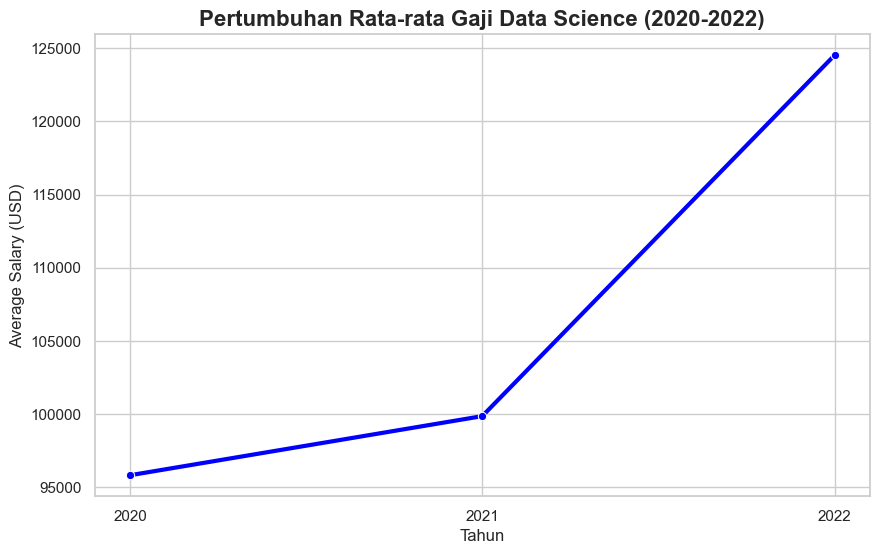

In [3]:
query_trend = """
SELECT
    work_year,
    AVG(salary_in_usd) as avg_salary
FROM ds_salaries
GROUP BY work_year
ORDER BY work_year ASC
"""

df_trend = pd.read_sql_query(query_trend, conn)

plt.figure(figsize=(10, 6))
sns.lineplot(data=df_trend, x='work_year', y='avg_salary', marker='o', linewidth=3, color='blue')
plt.title('Pertumbuhan Rata-rata Gaji Data Science (2020-2022)', fontsize=16, fontweight='bold')
plt.ylabel('Average Salary (USD)')
plt.xlabel('Tahun')
plt.xticks([2020, 2021, 2022])
plt.show()

### **2. Pengaruh Pengalaman terhadap Gaji**
**Pertanyaan:** Seberapa signifikan perbedaan gaji antara Junior, Mid-Level, Senior, dan Executive?

Kode Level:
* **EN:** Entry-level / Junior
* **MI:** Mid-level
* **SE:** Senior-level
* **EX:** Executive-level / Director

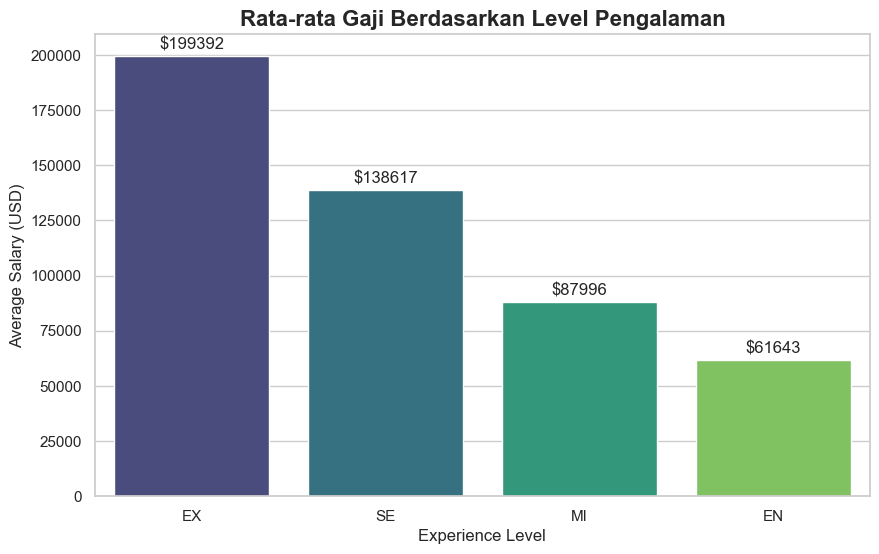

In [4]:
query_exp = """
SELECT
    experience_level,
    AVG(salary_in_usd) as avg_salary
FROM ds_salaries
GROUP BY experience_level
ORDER BY avg_salary DESC
"""

df_exp = pd.read_sql_query(query_exp, conn)

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_exp, x='experience_level', y='avg_salary', hue='experience_level', palette='viridis', legend=False)
plt.title('Rata-rata Gaji Berdasarkan Level Pengalaman', fontsize=16, fontweight='bold')
plt.ylabel('Average Salary (USD)')
plt.xlabel('Experience Level')

for i in ax.containers:
    ax.bar_label(i, fmt='$%.0f', padding=3)

plt.show()

### **3. Remote Work vs WFO**
**Pertanyaan:** Apakah bekerja secara Full Remote memberikan kompensasi yang lebih baik dibandingkan WFO atau Hybrid?

Kategori:
* **0:** WFO (Work From Office)
* **50:** Hybrid
* **100:** Full Remote

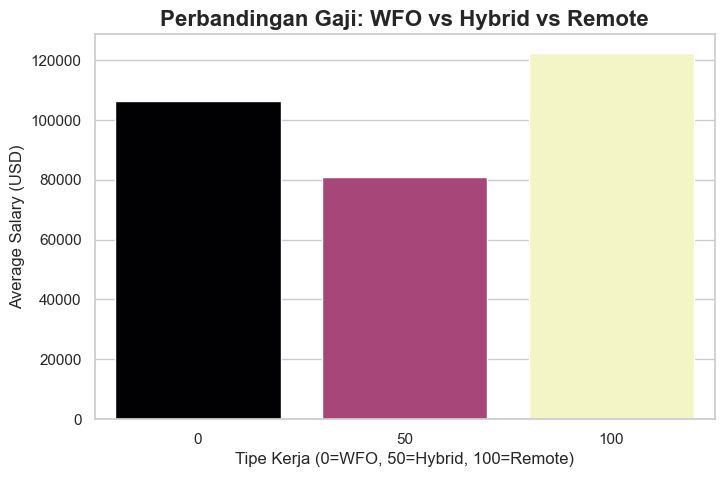

In [5]:
query_remote = """
SELECT
    remote_ratio,
    AVG(salary_in_usd) as avg_salary
FROM ds_salaries
GROUP BY remote_ratio
"""

df_remote = pd.read_sql_query(query_remote, conn)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_remote, x='remote_ratio', y='avg_salary', hue='remote_ratio', palette='magma', legend=False)
plt.title('Perbandingan Gaji: WFO vs Hybrid vs Remote', fontsize=16, fontweight='bold')
plt.xlabel('Tipe Kerja (0=WFO, 50=Hybrid, 100=Remote)')
plt.ylabel('Average Salary (USD)')
plt.show()

### **4. Top 5 Pekerjaan dengan Gaji Tertinggi**
**Pertanyaan:** Role apa saja yang memiliki rata-rata gaji tertinggi?

*Catatan: Kita memfilter pekerjaan yang minimal memiliki 3 data karyawan agar hasil rata-ratanya valid (tidak bias).*

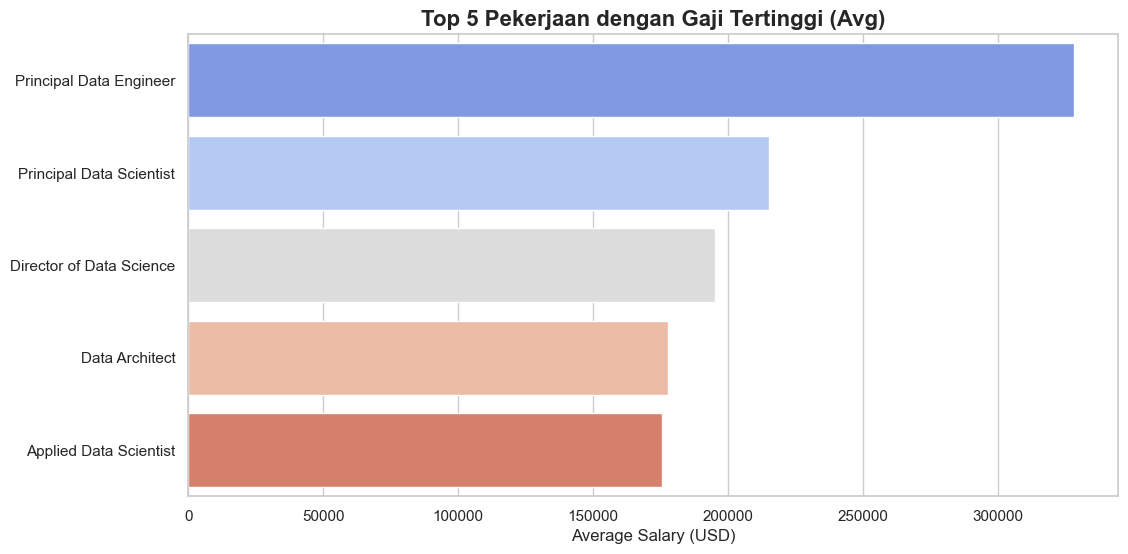

In [6]:
query_jobs = """
SELECT
    job_title,
    AVG(salary_in_usd) as avg_salary,
    COUNT(*) as total_employee
FROM ds_salaries
GROUP BY job_title
HAVING COUNT(*) >= 3
ORDER BY avg_salary DESC
LIMIT 5
"""

df_jobs = pd.read_sql_query(query_jobs, conn)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_jobs, y='job_title', x='avg_salary', hue='job_title', palette='coolwarm', legend=False)
plt.title('Top 5 Pekerjaan dengan Gaji Tertinggi (Avg)', fontsize=16, fontweight='bold')
plt.xlabel('Average Salary (USD)')
plt.ylabel('')
plt.show()

### **Kesimpulan Insight**
Berdasarkan analisis data di atas, kita dapat menyimpulkan:

1. **Tren Positif:** Industri data mengalami lonjakan gaji yang signifikan pada tahun 2022.
2. **Jenjang Karir:** Menjadi Senior (SE) atau Executive (EX) memberikan lompatan gaji yang sangat besar dibanding level Mid/Entry.
3. **Remote is King:** Bekerja secara Full Remote (100) ternyata memiliki rata-rata gaji tertinggi, kemungkinan dipengaruhi oleh perusahaan global yang merekrut talent dari berbagai negara dengan standar gaji tinggi.
4. **Role:** Posisi spesialis seperti *Principal Data Engineer* dan *Data Architect* menduduki peringkat atas gaji tertinggi.

In [7]:
conn.close()
print("SQLite connection closed cleanly.")

SQLite connection closed cleanly.
